# 🐈‍⬛ THINK / SELECT / RECLOSE — V21
**Squares in Squares · After the Reclose · Verified source-backed challenger**

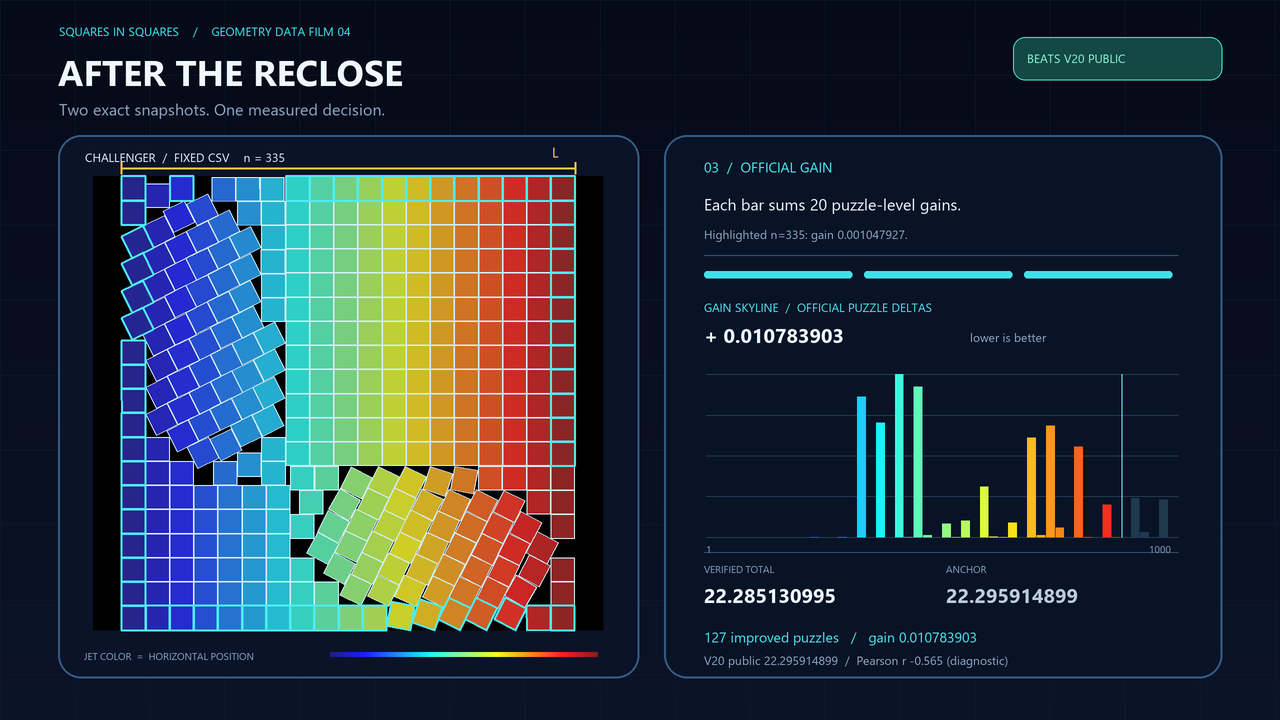

*The cover is a staged preview. The film below is regenerated from this run's exported `submission.csv`.*

> **Promotion gate:** beat the completed V20 public score **22.2959148987** and its exact, independently audited local certificate **22.29591489879818**. The V20 reconstruction is the primary fallback.


```text
       /\_/\
      ( o.o )   THINK  ->  SELECT  ->  RECLOSE
       > ^ <

  V13 certified ──> V20 exact reconstruction ──> V21 public witness
        │                    │                        │
        └── fallback 2       └── fallback 1           └── official gate

  1,000 puzzles  /  500,500 squares  /  lower metric is better
```

**What changed.** V21 reads two exact SHA-pinned numerical outputs from [Kirill Tymchishin's Square Packing Lab](https://www.kaggle.com/code/kirilltym/square-packing-lab-cpu-cuda-mps). The frozen older output reconstructs the published V20 portfolio byte for byte. The newer output is a separate challenger. Only complete puzzle blocks with a certified official gain are transferred; downloaded notebook code is never executed.

**Runtime contract.** CPU, no network during execution, deterministic source order, exact source hashes, official per-puzzle feasibility, full exported CSV schema, V20 rollback, then V13 fallback.


## 01 / Pinned inputs and official evaluator

In [1]:
import os, sys, csv, math, json, time, hashlib, shutil, importlib.util, platform
from pathlib import Path
import numpy as np

VERSION=21
COLS=['id','n','square_id','x','y','angle']
PUZZLES=1000
TOTAL_ROWS=500500
V13_SCORE=22.298736723156615
V20_SCORE=22.29591489879818
V20_SHA='42c3e7989761916bea86fac8c6a841d098c7c8a3917b632c409cfc40155be713'
V13_SHA='454d2a45b2b47264f8396a60be0aeaf347ec2b5b15bf9adf4c4eb9ab1b9b92a2'
METRIC_SHA='b22f141b63f76ceff60828ef2b4f7afaa29f1c4ac6b23aafc08a9c7d2103ace6'
MIN_GAIN=1e-11
MIN_SIDE_GAIN=1e-9
T0=time.perf_counter()
IN_DIRS=[p for p in [Path('/kaggle/input') if sys.platform.startswith('linux') else Path('v21_public_input')] if p.is_dir()]
WORK=Path('/kaggle/working') if sys.platform.startswith('linux') and Path('/kaggle/working').is_dir() else Path('artifacts/v21_run')
WORK.mkdir(parents=True,exist_ok=True)
OUTPUT=WORK/'submission.csv'
REPORT=WORK/'validation_v21.json'

def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda:f.read(1<<20),b''):h.update(b)
    return h.hexdigest()

def discover(pattern):
    return sorted({p for root in IN_DIRS for p in root.rglob(pattern) if p.is_file()},key=str)

metric_file=next((p for p in discover('official_metric.py') if sha(p)==METRIC_SHA),None)
if metric_file is None:
    raise FileNotFoundError('Pinned official_metric.py missing or SHA mismatch. Attach Think Select Reclose V13 Certified Inputs.')
spec=importlib.util.spec_from_file_location('metric_v16_pinned',metric_file)
metric=importlib.util.module_from_spec(spec)
sys.modules[spec.name]=metric
spec.loader.exec_module(metric)
if not hasattr(metric,'_evaluate_puzzle_worker'):
    raise AttributeError('The pinned evaluator API is unavailable')

print(' +--------------------------------------------------------------+')
print(' |  THINK  /  SELECT  /  RECLOSE                CHALLENGER V21  |')
print(' +--------------------------------------------------------------+')
print(f' [01] Official evaluator verified : {sha(metric_file)[:18]}..')

 +--------------------------------------------------------------+
 |  THINK  /  SELECT  /  RECLOSE                CHALLENGER V21  |
 +--------------------------------------------------------------+
 [01] Official evaluator verified : b22f141b63f76ceff6..


In [2]:
def read_puzzles(path):
    with Path(path).open('r',newline='',encoding='utf-8-sig') as f:
        r=csv.reader(f)
        if next(r,None)!=COLS:raise ValueError('Unexpected input columns: '+str(path))
        count=0
        for n in range(1,PUZZLES+1):
            block=[]
            for k in range(n):
                v=next(r,None)
                if v is None or len(v)!=6 or (int(v[0]),int(v[1]),int(v[2]))!=(count,n,k):
                    raise ValueError(f'Invalid row n={n}, square={k}, source={path}')
                if not all(math.isfinite(float(x)) for x in v[3:]):
                    raise ValueError('Non-finite geometry')
                block.append(tuple(v));count+=1
            yield block
        if count!=TOTAL_ROWS or next(r,None) is not None:
            raise ValueError('Incomplete/extra CSV rows')

def official(n,rows):
    result=metric._evaluate_puzzle_worker((n,[dict(zip(COLS,r)) for r in rows]))
    nn,score,side,status=result
    if nn!=n or status!='ok' or side is None or not math.isfinite(float(side)) or not math.isfinite(float(score)):
        raise ValueError(f'Official collision/feasibility rejection: n={n}: {result}')
    return float(score),float(side)

# Determine the angle units from the evaluator rather than assumptions.
sample=[('0','1','0','0','0',format(math.pi/4,'.17g'))]
_,probe=official(1,sample)
if abs(probe-math.sqrt(2))<1e-6: ANGLE_UNIT='radians'
elif abs(probe-(math.cos(math.radians(math.pi/4))+math.sin(math.radians(math.pi/4))))<1e-6: ANGLE_UNIT='degrees'
else:raise RuntimeError('Unknown evaluator angle convention')

def pose(rows):
    a=np.asarray([[float(r[3]),float(r[4]),float(r[5])] for r in rows],dtype=np.float64)
    if ANGLE_UNIT=='degrees':a[:,2]=np.deg2rad(a[:,2])
    return a

def extents(a):
    h=(np.abs(np.cos(a[:,2]))+np.abs(np.sin(a[:,2])))*.5
    return np.stack([a[:,0]-h,a[:,0]+h,a[:,1]-h,a[:,1]+h],axis=1)

def fast_side(rows):
    e=extents(pose(rows))
    return float(max(e[:,1].max()-e[:,0].min(),e[:,3].max()-e[:,2].min()))

# The public witness may be partial. Every missing puzzle inherits the
# hash-locked V13 block; no partial file is submitted alone.
def read_partial_puzzles(path):
    blocks={}
    with Path(path).open('r',newline='',encoding='utf-8-sig') as f:
        reader=csv.reader(f)
        if next(reader,None)!=COLS:raise ValueError('Unexpected witness columns')
        for row in reader:
            if len(row)!=6:raise ValueError('Malformed witness row')
            n,k=int(row[1]),int(row[2])
            if not 1<=n<=PUZZLES or k!=len(blocks.setdefault(n,[])):
                raise ValueError('Witness square order is invalid')
            if not all(math.isfinite(float(x)) for x in row[3:]):
                raise ValueError('Non-finite witness geometry')
            blocks[n].append((str(n*(n-1)//2+k),str(n),str(k),*row[3:]))
    if any(len(rows)!=n for n,rows in blocks.items()):
        raise ValueError('Incomplete witness puzzle')
    return blocks

all_csv=[p for p in discover('*.csv') if p.name.startswith('submission')
         and p.resolve()!=OUTPUT.resolve()]
anchor=next((p for p in all_csv if sha(p)==V13_SHA),None)
if anchor is None:
    raise FileNotFoundError('Certified V13 source CSV hash not found')
baseline=list(read_puzzles(anchor))
best=list(baseline)
base_side=np.array([fast_side(b) for b in baseline]);best_side=base_side.copy()
sources=[('V13',baseline)]
ignored=[]
witness_hashes={}
witnesses=[
    ('Kirill Frozen V27','dabb542b65680ea958e320d5d1c800bfe1c4c0ac8fcbeea961d2acce5797edcd'),
    ('Kirill New Root','2f3ac3d8c8412c29238671291c5972ecc92bd540c0e7c42f7e617b787522a93b'),
]
candidates=[p for p in all_csv if p.name=='submission.csv']
for name,expected_sha in witnesses:
    selected=next((p for p in candidates if sha(p)==expected_sha),None)
    if selected is None:
        ignored.append((name,'Missing or SHA-mismatched public witness'))
        continue
    try:
        patch=read_partial_puzzles(selected)
        sources.append((name,[patch.get(n,baseline[n-1]) for n in range(1,PUZZLES+1)]))
        witness_hashes[name]=expected_sha
        print(f' [01] {name}: {len(patch)} complete puzzle blocks, SHA verified')
    except Exception as exc:
        ignored.append((str(selected),repr(exc)))
print(f' [01] Certified V13 source       : {V13_SCORE:.12f}  (SHA verified)')
print(f' [01] V20 exact score gate       : {V20_SCORE:.12f}  (public: 22.2959148987)')
print(f' [01] Portfolio sources         : {len(sources)}')
print(f' [01] Angle convention          : {ANGLE_UNIT}')


 [01] Kirill Frozen V27: 547 complete puzzle blocks, SHA verified
 [01] Kirill New Root: 547 complete puzzle blocks, SHA verified
 [01] Certified V13 source       : 22.298736723157  (SHA verified)
 [01] V20 exact score gate       : 22.295914898798  (public: 22.2959148987)
 [01] Portfolio sources         : 3
 [01] Angle convention          : radians


## 02 / Two public witnesses · exact V20 reconstruction

Both numerical witnesses come from [Kirill Tymchishin's Square Packing Lab](https://www.kaggle.com/code/kirilltym/square-packing-lab-cpu-cuda-mps). The frozen V27 CSV has SHA-256 `dabb542b65680ea958e320d5d1c800bfe1c4c0ac8fcbeea961d2acce5797edcd`; the newer root CSV has SHA-256 `2f3ac3d8c8412c29238671291c5972ecc92bd540c0e7c42f7e617b787522a93b`. These are partial portfolios; missing puzzles inherit the certified V13 baseline. The older witness must reproduce the published V20 submission SHA exactly before a V21 promotion can occur.

Kirill's output includes `PORTFOLIO_NOTICES.md` crediting adopted public packings from Alex Chilton, Malyshev Danil, Sung Heo (`kmmmvs`), and Nilanjan Saha, plus their own upstream contributors. The attached V13 dataset retains earlier source notices. Credit for the numerical geometry belongs with those authors. This notebook adds whole-puzzle selection, exact official validation, rollback, and visualization; it does not run downloaded notebook code.


In [3]:
# V13 is hash-locked. Every proposed change is screened with the official evaluator.
base_score_cache={}
gain_by_n={}
accepted=[]
stats={'portfolio_tested':0,'portfolio_accepted':0,'rejected_by_official':0}
v20_snapshot=None

def propose(n,candidate,method):
    new_side=fast_side(candidate)
    if new_side>=best_side[n-1]-MIN_SIDE_GAIN:return False
    try:
        if n not in base_score_cache:
            base_score_cache[n]=official(n,baseline[n-1])[0]
        old_score=official(n,best[n-1])[0] if n in gain_by_n else base_score_cache[n]
        new_score,new_official_side=official(n,candidate)
        if new_score>=old_score-MIN_GAIN:return False
    except Exception:
        stats['rejected_by_official']+=1
        return False
    before=best_side[n-1]
    best[n-1]=candidate
    best_side[n-1]=new_official_side
    gain_by_n[n]=base_score_cache[n]-new_score
    accepted.append({'n':n,'method':method,'before_side':before,
                     'after_side':new_official_side,'gain_from_v13':gain_by_n[n]})
    print(f'   [+] n={n:4d} | {method:<22} | side {before:.8f} -> {new_official_side:.8f}')
    return True

for label,blocks in sources[1:]:
    improved=0
    for n,candidate in enumerate(blocks,1):
        if fast_side(candidate)<best_side[n-1]-MIN_SIDE_GAIN:
            stats['portfolio_tested']+=1
            if propose(n,candidate,'portfolio:'+label[:14]):improved+=1
    stats['portfolio_accepted']+=improved
    print(f' [02] {label[:25]:25s} {improved} verified transfers')
    if label=='Kirill Frozen V27':
        v20_snapshot=[list(block) for block in best]

print(f' [02] Officially accepted transfers: {stats["portfolio_accepted"]}')
print(f' [02] V20 snapshot available      : {v20_snapshot is not None}')


   [+] n= 232 | portfolio:Kirill Frozen  | side 15.76417432 -> 15.76338145
   [+] n= 260 | portfolio:Kirill Frozen  | side 16.64575325 -> 16.63854399
   [+] n= 268 | portfolio:Kirill Frozen  | side 16.87436173 -> 16.87436172
   [+] n= 299 | portfolio:Kirill Frozen  | side 17.82287566 -> 17.80369547
   [+] n= 303 | portfolio:Kirill Frozen  | side 17.90697825 -> 17.90697824
   [+] n= 334 | portfolio:Kirill Frozen  | side 18.79311520 -> 18.79311520
   [+] n= 338 | portfolio:Kirill Frozen  | side 18.88508894 -> 18.88402546
   [+] n= 343 | portfolio:Kirill Frozen  | side 18.97717160 -> 18.97717159
   [+] n= 370 | portfolio:Kirill Frozen  | side 19.76417432 -> 19.76417432
   [+] n= 371 | portfolio:Kirill Frozen  | side 19.77817460 -> 19.77817459
   [+] n= 372 | portfolio:Kirill Frozen  | side 19.80612157 -> 19.80612155
   [+] n= 375 | portfolio:Kirill Frozen  | side 19.87001387 -> 19.87001385
   [+] n= 376 | portfolio:Kirill Frozen  | side 19.88875173 -> 19.88787007
   [+] n= 377 | portfolio

## 03 / Bounded search decision

The fresh public numerical witness already has a positive official-metric preflight. V21 does not launch an unbounded solver or require a GPU. The 4-core Kaggle CPU run only selects and validates complete puzzle blocks, then renders the result. Every source is SHA-pinned and the public/private leaderboard uncertainty remains explicit.


In [4]:
print(' [03] Bounded CPU portfolio selection complete; no optional solver is required.')

 [03] Bounded CPU portfolio selection complete; no optional solver is required.


## 04 / Transactional export and V20 promotion gate

In [5]:
def write_blocks(path,blocks):
    with Path(path).open('w',newline='',encoding='utf-8') as f:
        w=csv.writer(f,lineterminator='\n');w.writerow(COLS)
        for block in blocks:w.writerows(block)

v20_anchor_path=WORK/'v20_anchor_reconstructed.csv'
v20_valid=False
rollback_reason=None
if v20_snapshot is not None:
    write_blocks(v20_anchor_path,v20_snapshot)
    v20_valid=(sha(v20_anchor_path)==V20_SHA)
    if not v20_valid:rollback_reason='V20 reconstruction SHA mismatch'
else:
    rollback_reason='Frozen V20 numerical witness unavailable'

v21_changed=[]
v21_gain={}
status='rollback_to_v20' if v20_valid else 'rollback_to_v13'
fallback_path=v20_anchor_path if v20_valid else anchor
fallback_score=V20_SCORE if v20_valid else V13_SCORE
final_score=fallback_score
if v20_valid:
    v21_changed=[n for n in range(1,PUZZLES+1) if best[n-1]!=v20_snapshot[n-1]]
    if v21_changed:
        tmp=WORK/'submission_v21_candidate.csv'
        try:
            write_blocks(tmp,best)
            if sum(len(block) for block in read_puzzles(tmp))!=TOTAL_ROWS:
                raise ValueError('Candidate row count mismatch')
            candidate_blocks={n:block for n,block in enumerate(read_puzzles(tmp),1)
                              if n in v21_changed}
            for n in v21_changed:
                before,_=official(n,v20_snapshot[n-1])
                after,_=official(n,candidate_blocks[n])
                gain=before-after
                if gain<=MIN_GAIN:raise ValueError(f'No certified gain at n={n}')
                v21_gain[n]=gain
            candidate_score=V20_SCORE-math.fsum(v21_gain.values())
            if candidate_score>=V20_SCORE-MIN_GAIN:
                raise ValueError('V21 did not beat the completed V20 gate')
            v13_derived=V13_SCORE-math.fsum(gain_by_n.values())
            if abs(candidate_score-v13_derived)>1e-8:
                raise ValueError('V13 and V20 score paths disagree')
            os.replace(tmp,OUTPUT)
            final_score=candidate_score
            status='verified_improvement'
            rollback_reason=None
        except Exception as exc:
            rollback_reason=repr(exc)
        finally:
            if tmp.exists():tmp.unlink()
    else:
        rollback_reason='No V21 puzzle improves V20'
if status!='verified_improvement':
    shutil.copyfile(fallback_path,OUTPUT)
    v21_gain={}
    v21_changed=[]
    final_score=fallback_score

assert sum(len(block) for block in read_puzzles(OUTPUT))==TOTAL_ROWS
assert math.isfinite(final_score)
if status=='rollback_to_v20':assert sha(OUTPUT)==V20_SHA
if status=='rollback_to_v13':assert sha(OUTPUT)==V13_SHA
report={
    'version':VERSION,'status':status,'v13_score':V13_SCORE,
    'v20_score':V20_SCORE,'final_score':final_score,
    'delta_to_v20':final_score-V20_SCORE,
    'v20_reconstructed':v20_valid,'v20_sha256':V20_SHA,
    'output_sha256':sha(OUTPUT),'metric_sha256':METRIC_SHA,
    'rows':TOTAL_ROWS,'puzzles':PUZZLES,
    'changed_puzzles_officially_rescored':len(v21_gain),
    'changed_puzzle_ids':v21_changed,'gain_per_puzzle':v21_gain,
    'attempts_and_acceptance':stats,'accepted_log':accepted,
    'input_sources':[name for name,_ in sources],
    'witness_sha256':witness_hashes,'ignored_sources':ignored,
    'rollback_reason':rollback_reason,
    'environment':{'python':sys.version,'numpy':np.__version__,
                   'platform':platform.platform(),'logical_cpus':os.cpu_count()},
    'wall_seconds':time.perf_counter()-T0,
    'limitations':'Private leaderboard unobserved. No proof of global optimality.'
}
try:
    import resource
    report['environment']['peak_rss_mib']=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024
except ImportError:
    report['environment']['peak_rss_mib']=None
REPORT.write_text(json.dumps(report,indent=2,ensure_ascii=False,default=float),encoding='utf-8')
print('')
print(' +--------------------------------------------------------------+')
print(' |                    V21 / OFFICIAL REPORT                     |')
print(' +--------------------------------------------------------------+')
print(f' |  V20 anchor score        {V20_SCORE:>18.12f}                |')
print(f' |  V21 final score         {final_score:>18.12f}                |')
print(f' |  delta (lower better)    {final_score-V20_SCORE:>+18.12f}                |')
print(f' |  improved puzzles       {len(v21_gain):>18,d}                |')
print(' +--------------------------------------------------------------+')
print(f' [04] Status          : {status}')
print(f' [04] Submission      : {OUTPUT} ({TOTAL_ROWS:,} rows)')
print(f' [04] SHA-256         : {sha(OUTPUT)}')
print(f' [04] Audit           : {REPORT.name}')



 +--------------------------------------------------------------+
 |                    V21 / OFFICIAL REPORT                     |
 +--------------------------------------------------------------+
 |  V20 anchor score           22.295914898798                |
 |  V21 final score            22.285130995497                |
 |  delta (lower better)       -0.010783903301                |
 |  improved puzzles                      127                |
 +--------------------------------------------------------------+
 [04] Status          : verified_improvement
 [04] Submission      : /kaggle/working/submission.csv (500,500 rows)
 [04] SHA-256         : d4f93e340f63093f30d7029c17cbfe1fb8cdaa7c9f6643ee253c7f0e204bea1e
 [04] Audit           : validation_v21.json


## 05 / Final geometry · actual exported CSV

The following jet plot reads the exported coordinates. It is descriptive; only the official collision test decides promotion.


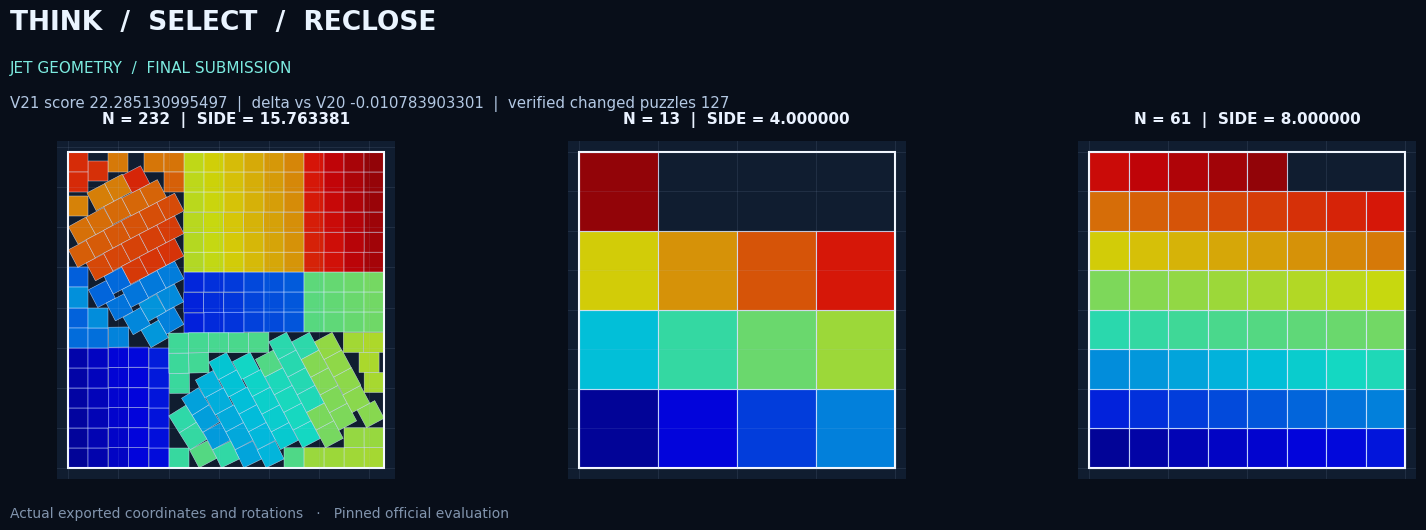

 [05] Geometric visualization: packing_v21.png


In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle

plot_ns=([v21_changed[0]] if v21_changed and status=='verified_improvement' else [])
plot_ns=list(dict.fromkeys(plot_ns+[13,61,169]))[:3]
example={n:block for n,block in enumerate(read_puzzles(OUTPUT),1) if n in plot_ns}
palette=plt.get_cmap('jet')(np.linspace(.04,.96,max(plot_ns)))
fig,axes=plt.subplots(1,len(plot_ns),figsize=(15.3,5.45),facecolor='#080e19')
fig.subplots_adjust(left=.04,right=.99,top=.74,bottom=.12,wspace=.18)
if len(plot_ns)==1:axes=[axes]
for ax,n in zip(axes,plot_ns):
    ax.set_facecolor('#101d30')
    a=pose(example[n]);ext=extents(a)
    xmin,ymin=ext[:,0].min(),ext[:,2].min()
    width=ext[:,1].max()-xmin;height=ext[:,3].max()-ymin
    side=float(max(width,height))
    q=np.array([[-.5,-.5],[.5,-.5],[.5,.5],[-.5,.5]])
    for k,(x,y,t) in enumerate(a):
        c,s=np.cos(t),np.sin(t)
        poly=q@np.array([[c,s],[-s,c]])+np.array([x,y])
        ax.add_patch(Polygon(poly,closed=True,facecolor=plt.get_cmap('jet')(.04+.92*k/max(1,n-1)),
                             alpha=.83,edgecolor='#d5e5ff',linewidth=.35 if n>80 else .8))
    ax.add_patch(Rectangle((xmin,ymin),side,side,fill=False,lw=1.5,edgecolor='#f5f9ff'))
    border=.035*side
    ax.set(xlim=(xmin-border,xmin+side+border),ylim=(ymin-border,ymin+side+border))
    ax.set_aspect('equal',adjustable='box')
    ax.set_title(f'N = {n}  |  SIDE = {side:.6f}',color='#eaf2ff',fontweight='bold',fontsize=11,pad=13)
    ax.grid(alpha=.10,color='#afc6ed')
    ax.tick_params(left=False,bottom=False,labelleft=False,labelbottom=False)
    for spine in ax.spines.values():spine.set_visible(False)
fig.text(.04,.945,'THINK  /  SELECT  /  RECLOSE',color='#eaf4ff',fontsize=19,weight='bold')
fig.text(.04,.866,'JET GEOMETRY  /  FINAL SUBMISSION',color='#7cebe0',fontsize=11)
fig.text(.04,.802,f'V21 score {final_score:.12f}  |  delta vs V20 {final_score-V20_SCORE:+.12f}  |  verified changed puzzles {len(v21_gain)}',color='#b3c8e3',fontsize=10.8)
fig.text(.04,.050,'Actual exported coordinates and rotations   ·   Pinned official evaluation',color='#8194ad',fontsize=10)
chart_file=WORK/'packing_v21.png'
fig.savefig(chart_file,dpi=150,bbox_inches='tight',facecolor=fig.get_facecolor())
plt.show()
print(f' [05] Geometric visualization: {chart_file.name}')

## 06 / After the Reclose · two exact snapshots

The GIF cuts between the exact V20 and V21 coordinate files. It never interpolates squares. Jet color shows horizontal position; the skyline sums **official gains against V20** in groups of 20 puzzle sizes. The Pearson footer is a descriptive diagnostic only. A certified badge appears only after the promotion gate. The animation is regenerated from this run's `submission.csv` and displayed inline.


 [06] Motion study: v21_inside_boundary.gif  |  32 frames
 [06] Pearson diagnostic: -0.565


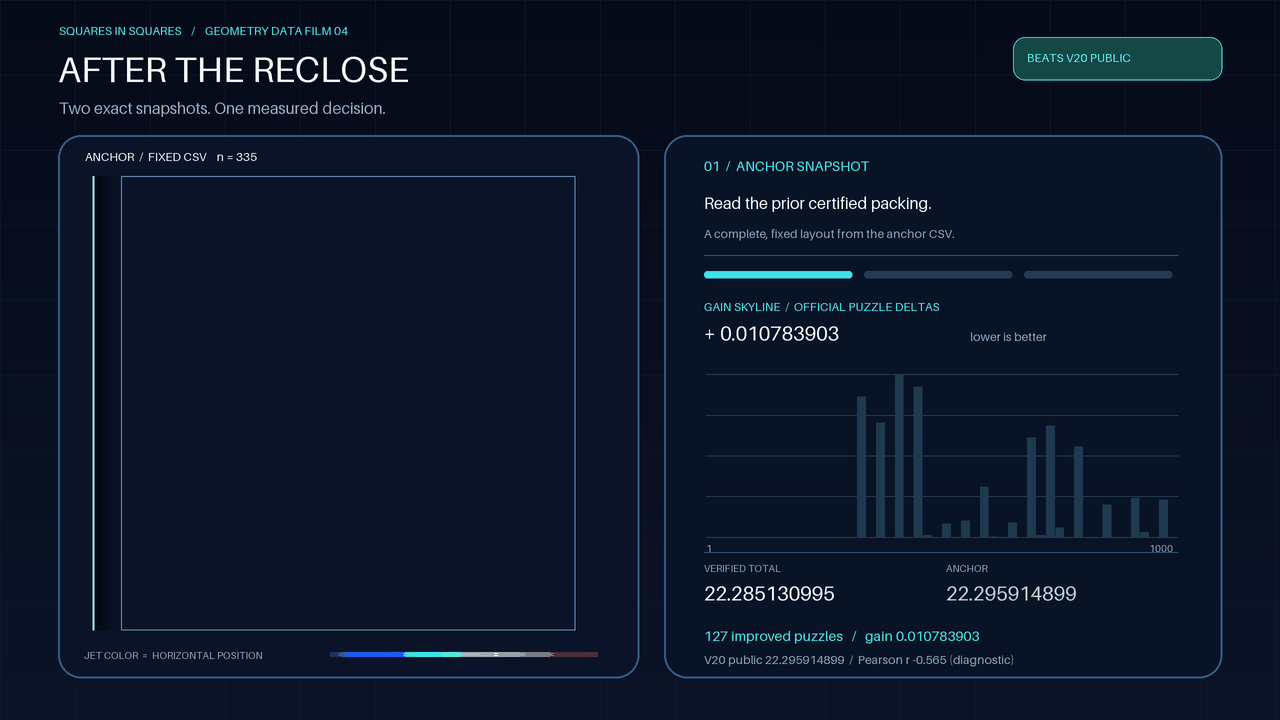

In [7]:
"""Cinematic, source-backed jet animation for Squares in Squares.

The source can be inlined into a Kaggle notebook. Call render_v21_story_gif only
after writing and validating submission.csv. The three acts change lighting and
annotations around *fixed* final polygons; no intermediate packing is invented.
Pearson r is descriptive and is never used as evidence of search improvement.
"""

from __future__ import annotations

import csv
import hashlib
import math
from pathlib import Path

from PIL import Image, ImageDraw, ImageFont


V21_SIZE = (1280, 720)
V21_SCALE = 2


def _v21_font(size, bold=False):
    choices = (["C:/Windows/Fonts/segoeuib.ttf",
                "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"] if bold
               else ["C:/Windows/Fonts/segoeui.ttf",
                     "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"])
    for candidate in choices:
        if Path(candidate).exists():
            return ImageFont.truetype(candidate, size * V21_SCALE)
    return ImageFont.load_default(size=size * V21_SCALE)


def _v21_jet(t):
    t = min(1., max(0., t))
    rgb = [min(1., max(0., 1.5 - abs(4 * t - offset)))
           for offset in (3., 2., 1.)]
    return tuple(round(29 + 220 * c) for c in rgb)


def _v21_vertices(x, y, angle):
    c, s = math.cos(angle), math.sin(angle)
    return [(x + dx * c - dy * s, y + dx * s + dy * c)
            for dx, dy in ((-.5, -.5), (.5, -.5), (.5, .5), (-.5, .5))]


def _v21_read_submission(path, featured_n):
    """Check all 500,500 row IDs and collect only the featured packing."""
    expected = ["id", "n", "square_id", "x", "y", "angle"]
    scores = []
    selected = []
    previous_n = 1
    square_id = 0
    row_id = 0
    bounds = [math.inf, -math.inf, math.inf, -math.inf]

    def finish(n, count, edge):
        if count != n:
            raise ValueError(f"Incomplete puzzle n={n}")
        side = max(edge[1] - edge[0], edge[3] - edge[2])
        return side / math.sqrt(n) - 1.

    with Path(path).open(newline="", encoding="utf-8-sig") as handle:
        reader = csv.DictReader(handle)
        if reader.fieldnames != expected:
            raise ValueError("Unexpected submission schema")
        for row in reader:
            n, sid, rid = int(row["n"]), int(row["square_id"]), int(row["id"])
            if n != previous_n:
                if n != previous_n + 1:
                    raise ValueError("Missing or reordered puzzle")
                scores.append(finish(previous_n, square_id, bounds))
                previous_n, square_id = n, 0
                bounds = [math.inf, -math.inf, math.inf, -math.inf]
            if rid != row_id or sid != square_id:
                raise ValueError(f"Row or square ID mismatch at row {row_id}")
            x, y, angle = float(row["x"]), float(row["y"]), float(row["angle"])
            if not all(math.isfinite(v) for v in (x, y, angle)):
                raise ValueError("Nonfinite packing coordinate")
            vertices = _v21_vertices(x, y, angle)
            for vx, vy in vertices:
                bounds[0] = min(bounds[0], vx)
                bounds[1] = max(bounds[1], vx)
                bounds[2] = min(bounds[2], vy)
                bounds[3] = max(bounds[3], vy)
            if n == featured_n:
                selected.append((sid, vertices))
            row_id += 1
            square_id += 1
    if square_id:
        scores.append(finish(previous_n, square_id, bounds))
    if row_id != 500_500 or len(scores) != 1000 or len(selected) != featured_n:
        raise ValueError("Submission is not a complete 1,000 puzzle portfolio")
    return selected, scores


def _v21_pearson(scores):
    points = [(float(n), scores[n-1]) for n in range(20, 1001)]
    mx = sum(x for x, _ in points) / len(points)
    my = sum(y for _, y in points) / len(points)
    covariance = sum((x-mx) * (y-my) for x, y in points)
    xx = sum((x-mx)**2 for x, _ in points)
    yy = sum((y-my)**2 for _, y in points)
    return covariance / math.sqrt(xx * yy)


def render_v21_story_gif(
    submission_path,
    output_dir,
    score,
    anchor_score,
    changed_ids,
    *,
    anchor_submission_path=None,
    gain_by_n=None,
    promotion_score=None,
    featured_n=None,
    certified=False,
    frames=32,
    frame_duration_ms=120,
):
    """Return GIF/PNG paths and diagnostics for a verified final portfolio.

    `certified=True` is appropriate only after the caller's official metric gate.
    If changed_ids is empty, a representative complete puzzle is still shown.
    """
    if not 24 <= frames <= 48:
        raise ValueError("frames must be in [24, 48]")
    if not all(math.isfinite(float(v)) for v in (score, anchor_score)):
        raise ValueError("Portfolio scores must be finite")
    if promotion_score is not None and not math.isfinite(float(promotion_score)):
        raise ValueError("promotion_score must be finite")
    promoted = (certified and promotion_score is not None and
                float(score) < float(promotion_score) - 1e-9)
    changed = sorted({int(n) for n in changed_ids if 1 <= int(n) <= 1000})
    if featured_n is None:
        featured_n = min(changed, key=lambda n: abs(n - 580)) if changed else 415
    featured_n = int(featured_n)
    if not 1 <= featured_n <= 1000:
        raise ValueError("featured_n must be a valid puzzle")
    selected, scores = _v21_read_submission(submission_path, featured_n)
    measured_total = math.fsum(scores)
    if abs(measured_total - float(score)) > 1e-6:
        raise ValueError("Displayed total differs from final serialized geometry")
    if certified and (anchor_submission_path is None or gain_by_n is None):
        raise ValueError("Certified before/after film needs anchor CSV and official gains")
    anchor_selected = None
    anchor_scores = None
    if anchor_submission_path is not None:
        anchor_selected, anchor_scores = _v21_read_submission(
            anchor_submission_path, featured_n)
        if abs(math.fsum(anchor_scores) - float(anchor_score)) > 1e-6:
            raise ValueError("Displayed anchor differs from its serialized geometry")
    gains = {int(n): float(v) for n, v in (gain_by_n or {}).items()}
    if any(n < 1 or n > 1000 or not math.isfinite(v) or v < -1e-10
           for n, v in gains.items()):
        raise ValueError("Invalid official gain map")
    if certified:
        if set(gains) != set(changed):
            raise ValueError("Changed IDs and official gain map disagree")
        if abs(math.fsum(gains.values()) -
               (float(anchor_score)-float(score))) > 1e-6:
            raise ValueError("Official gain map does not reconcile to total score")
    else:
        gains = {}
        changed = []
    pearson = _v21_pearson(scores)
    vertices = [point for _, poly in selected for point in poly]
    xs, ys = zip(*vertices)
    bounds = (min(xs), max(xs), min(ys), max(ys))
    bx0, bx1, by0, by1 = bounds
    side = max(bx1 - bx0, by1 - by0)
    if anchor_selected is not None:
        anchor_vertices = [p for _, poly in anchor_selected for p in poly]
        ax, ay = zip(*anchor_vertices)
        ax0, ax1, ay0, ay1 = min(ax), max(ax), min(ay), max(ay)
        anchor_side = max(ax1-ax0, ay1-ay0)
    else:
        ax0, ax1, ay0, ay1 = bx0, bx1, by0, by1
        anchor_side = side
    S = V21_SCALE
    W, H = V21_SIZE[0] * S, V21_SIZE[1] * S
    area = (93, 176, 603, 630)
    common_side = max(side, anchor_side)
    factor = min((area[2]-area[0]) / common_side,
                 (area[3]-area[1]) / common_side)
    left = area[0] + ((area[2]-area[0]) - factor*(bx1-bx0))/2
    top = area[1] + ((area[3]-area[1]) - factor*(by1-by0))/2
    anchor_left = area[0] + ((area[2]-area[0]) - factor*(ax1-ax0))/2
    anchor_top = area[1] + ((area[3]-area[1]) - factor*(ay1-ay0))/2

    def screen(poly):
        return [(round((left + (x-bx0)*factor)*S),
                 round((top + (by1-y)*factor)*S)) for x, y in poly]

    def screen_anchor(poly):
        return [(round((anchor_left + (x-ax0)*factor)*S),
                 round((anchor_top + (ay1-y)*factor)*S)) for x, y in poly]

    # Static data layers are built once; motion never changes a coordinate.
    backdrop = Image.new("RGB", (W, H), (6, 10, 24))
    bd = ImageDraw.Draw(backdrop)
    for y in range(H):
        t = y / H
        bd.line((0, y, W, y), fill=(round(5+6*t), round(10+9*t), round(24+15*t)))
    for x in range(0, W, 75*S):
        bd.line((x, 0, x, H), fill=(17, 27, 48), width=1)
    for y in range(0, H, 75*S):
        bd.line((0, y, W, y), fill=(17, 27, 48), width=1)
    bd.rounded_rectangle((58*S, 135*S, 639*S, 678*S), radius=23*S,
                         fill=(10, 19, 39), outline=(51, 92, 132), width=2*S)
    bd.rounded_rectangle((664*S, 135*S, 1222*S, 678*S), radius=23*S,
                         fill=(9, 19, 38), outline=(51, 92, 132), width=2*S)

    f10 = _v21_font(10)
    f12 = _v21_font(12)
    f14 = _v21_font(14)
    f16 = _v21_font(16)
    f20 = _v21_font(20, True)
    f36 = _v21_font(36, True)
    bd.text((59*S, 23*S), "SQUARES IN SQUARES    /    GEOMETRY DATA FILM 04",
            font=f12, fill=(64, 230, 239))
    bd.text((58*S, 47*S), "AFTER THE RECLOSE", font=f36, fill=(239, 247, 255))
    bd.text((59*S, 98*S), "Two exact snapshots. One measured decision.",
            font=f16, fill=(139, 166, 195))
    if certified:
        bd.rounded_rectangle((1013*S, 37*S, 1222*S, 80*S), radius=12*S,
                             fill=(20, 72, 69), outline=(73, 231, 190), width=S)
        bd.text((1027*S, 50*S),
                "BEATS V20 PUBLIC" if promoted else "OFFICIAL GATE PASSED",
                font=f12,
                fill=(134, 249, 209))
    bd.text((84*S, 649*S), "JET COLOR  =  HORIZONTAL POSITION",
            font=f10, fill=(135, 164, 191))
    for k in range(160):
        x = round((330 + 1.67*k)*S)
        bd.line((x, 654*S, x+2*S, 654*S), fill=_v21_jet(k/159), width=5*S)

    # Both portfolios remain fixed snapshots. A hard cut switches between them.
    geometry_dim = Image.new("RGBA", (W, H), (0, 0, 0, 0))
    geometry_bright = Image.new("RGBA", (W, H), (0, 0, 0, 0))
    dim_draw, bright_draw = ImageDraw.Draw(geometry_dim), ImageDraw.Draw(geometry_bright)
    anchor_bright = Image.new("RGBA", (W, H), (0, 0, 0, 0))
    anchor_draw = ImageDraw.Draw(anchor_bright)
    for sid, poly in (anchor_selected or selected):
        q = screen_anchor(poly)
        center_x = sum(x for x, _ in poly) / 4
        color = _v21_jet((center_x-ax0)/(ax1-ax0))
        anchor_draw.polygon(q, fill=tuple(round(c*.72+14) for c in color)+(255,),
                            outline=(197, 217, 239, 255), width=S)
    hull_polys = []
    tolerance = max(2e-6, side * 1e-7)
    for sid, poly in selected:
        q = screen(poly)
        center_x = sum(x for x, _ in poly) / 4
        color = _v21_jet((center_x-bx0)/(bx1-bx0))
        dim_draw.polygon(q, fill=tuple(round(c*.26) for c in color)+(255,),
                         outline=(43, 68, 94, 255), width=S)
        bright_draw.polygon(q, fill=tuple(round(c*.77+15) for c in color)+(255,),
                            outline=(212, 238, 252, 255), width=S)
        if any(abs(x-bx0)<tolerance or abs(x-bx1)<tolerance or
               abs(y-by0)<tolerance or abs(y-by1)<tolerance for x, y in poly):
            hull_polys.append(q)
    full = Image.alpha_composite(backdrop.convert("RGBA"), geometry_dim)
    fd = ImageDraw.Draw(full)
    rect = (round(left*S), round(top*S),
            round((left+(bx1-bx0)*factor)*S),
            round((top+(by1-by0)*factor)*S))
    hull_center = ((rect[0]+rect[2])/2, (rect[1]+rect[3])/2)
    hull_polys.sort(key=lambda p: math.atan2(
        sum(y for _, y in p)/len(p)-hull_center[1],
        sum(x for x, _ in p)/len(p)-hull_center[0]))
    anchor_rect = (round(anchor_left*S), round(anchor_top*S),
                   round((anchor_left+(ax1-ax0)*factor)*S),
                   round((anchor_top+(ay1-ay0)*factor)*S))
    fd.rectangle(rect, outline=(73, 142, 175, 255), width=S)

    # Official per-puzzle gains, grouped into 20-puzzle bins for legibility.
    chart = (706, 374, 1178, 537)
    gain_bins = [math.fsum(gains.get(n, 0.) for n in range(1+20*k, 21+20*k))
                 for k in range(50)]
    gain_max = max(gain_bins) if gain_bins else 0.
    for frac in (0., .25, .5, .75, 1.):
        yy = chart[3] - frac*(chart[3]-chart[1])
        fd.line((chart[0]*S, round(yy*S), chart[2]*S, round(yy*S)),
                fill=(35, 58, 83), width=S)
    bars = []
    for k, gain in enumerate(gain_bins):
        x0 = round((chart[0] + k*(chart[2]-chart[0])/50)*S)
        x1 = round((chart[0] + (k+1)*(chart[2]-chart[0])/50 - 1)*S)
        height = gain/gain_max*(chart[3]-chart[1]) if gain_max>0 else 0.
        y0 = round((chart[3]-height)*S)
        bars.append((k, x0, x1, y0))
        if gain>0:
            fd.rectangle((x0, y0, x1, chart[3]*S), fill=(31, 57, 79, 255))

    # Compact, verified metrics. The requested total is checked against CSV.
    fd.line((704*S, 552*S, 1178*S, 552*S), fill=(48, 82, 113), width=S)
    fd.text((704*S, 562*S), "VERIFIED TOTAL" if certified else "FINAL TOTAL",
            font=f10, fill=(133, 163, 191))
    fd.text((704*S, 581*S), f"{float(score):.9f}", font=f20, fill=(238, 248, 255))
    fd.text((946*S, 562*S), "ANCHOR", font=f10, fill=(133, 163, 191))
    fd.text((946*S, 581*S), f"{float(anchor_score):.9f}", font=f20,
            fill=(187, 204, 225))
    fd.text((704*S, 627*S),
            (f"{len(changed)} improved puzzles   /   gain {float(anchor_score)-float(score):.9f}"
             if certified else "Preview only  /  no official gain claimed"),
            font=f14, fill=(74, 229, 237))
    footer = (f"V20 public {float(promotion_score):.9f}  /  Pearson r {pearson:+.3f} (diagnostic)"
              if promotion_score is not None else
              f"Pearson r(size, excess) = {pearson:+.3f}  /  diagnostic only")
    fd.text((704*S, 652*S), footer,
            font=f12, fill=(139, 166, 195))

    anchor_full = full.copy()
    ad = ImageDraw.Draw(anchor_full)
    ad.rectangle((80*S, 174*S, 615*S, 635*S), fill=(10, 19, 39, 255))
    ad.rectangle(anchor_rect, outline=(100, 144, 185, 255), width=S)

    featured_gain = gains.get(featured_n, 0.)
    act_text = [
        ("01  /  ANCHOR SNAPSHOT" if anchor_selected is not None
         else "01  /  REFERENCE SNAPSHOT",
         "Read the prior certified packing." if anchor_selected is not None
         else "Read the final packing as a reference.",
         "A complete, fixed layout from the anchor CSV." if anchor_selected is not None
         else "No separate anchor CSV was supplied."),
        ("02  /  CHALLENGER SNAPSHOT" if certified else "02  /  FINAL SNAPSHOT",
         "Now read the final certified packing." if certified
         else "Now read the final submitted packing.",
         "A discrete cut, never an interpolated layout."),
        ("03  /  OFFICIAL GAIN" if certified else "03  /  NO CERTIFIED GAIN",
         "Each bar sums 20 puzzle-level gains." if certified
         else "No official gain map is shown in preview mode.",
         (f"Highlighted n={featured_n}: gain {featured_gain:.9f}."
          if certified else "Only metric-verified gains enter this skyline.")),
    ]
    rendered = []
    preview = None
    for index in range(frames):
        t = index / max(1, frames-1)
        act = min(2, int(t*3))
        within = t*3 - act
        frame = anchor_full.copy() if act == 0 else full.copy()

        # A hard cut separates source snapshots; only lighting moves.
        reveal = min(1., t * 3.25) if act == 0 else 1.
        scan_x = round((area[0]+reveal*(area[2]-area[0]))*S)
        mask = Image.new("L", (W, H), 0)
        md = ImageDraw.Draw(mask)
        md.rectangle((area[0]*S, area[1]*S, scan_x, area[3]*S), fill=255)
        if act == 0:
            for offset in range(1, 25*S):
                md.line((scan_x+offset, area[1]*S, scan_x+offset, area[3]*S),
                        fill=round(160*(1-offset/(25*S))), width=1)
        frame = Image.composite(anchor_bright if act == 0 else geometry_bright,
                                frame, mask)
        draw = ImageDraw.Draw(frame)

        if act == 0:
            draw.line((scan_x, area[1]*S, scan_x, area[3]*S),
                      fill=(156, 250, 255, 180), width=2*S)
        if act >= 1:
            pulse = .55 + .45*math.sin(index*math.pi/4)**2
            visible_hull = (max(1, round(len(hull_polys)*within))
                            if act == 1 else len(hull_polys))
            for poly in hull_polys[:visible_hull]:
                draw.line(poly+[poly[0]], fill=(78, 237, 244, round(195*pulse)),
                          width=2*S, joint="curve")
            # The bracket grows to the true measured bounds, never moving tiles.
            bracket_right = (round(rect[0]+within*(rect[2]-rect[0]))
                             if act == 1 else rect[2])
            draw.line((rect[0], rect[1]-8*S, bracket_right, rect[1]-8*S),
                      fill=(255, 196, 69, 220), width=2*S)
            for x in (rect[0], bracket_right):
                draw.line((x, rect[1]-14*S, x, rect[1]-2*S),
                          fill=(255, 196, 69, 220), width=2*S)
            draw.text((rect[2]-23*S, rect[1]-34*S), "L", font=f14,
                      fill=(255, 205, 84, 255))

        if act == 2:
            active_bin = min(49, round(49*within))
            for k, x0, x1, y0 in bars:
                if k <= active_bin and gain_bins[k] > 0:
                    draw.rectangle((x0, y0, x1, chart[3]*S),
                                   fill=_v21_jet(k/49)+(245,))
            cursor = round((chart[0] + active_bin*(chart[2]-chart[0])/50)*S)
            draw.line((cursor, chart[1]*S, cursor, chart[3]*S),
                      fill=(97, 242, 245, 170), width=S)

        title, line1, line2 = act_text[act]
        left_label = ("ANCHOR  /  FIXED CSV" if act == 0 else
                      "CHALLENGER  /  FIXED CSV")
        draw.text((85*S, 149*S), f"{left_label}    n = {featured_n}",
                  font=f12, fill=(225, 239, 255))
        draw.text((704*S, 157*S), title, font=f14, fill=(70, 235, 240))
        draw.text((704*S, 193*S), line1, font=f16, fill=(235, 245, 255))
        draw.text((704*S, 226*S), line2, font=f12, fill=(138, 168, 195))
        draw.line((704*S, 255*S, 1178*S, 255*S), fill=(51, 87, 116), width=S)
        for step in range(3):
            x0 = (704 + step*160)*S
            fill = (64, 225, 234, 255) if step <= act else (36, 59, 83, 255)
            draw.rounded_rectangle((x0, 271*S, x0+148*S, 278*S),
                                   radius=3*S, fill=fill)
        draw.text((704*S, 299*S),
                  "GAIN SKYLINE  /  OFFICIAL PUZZLE DELTAS" if certified
                  else "GAIN SKYLINE  /  CERTIFICATION PENDING", font=f12,
                  fill=(78, 227, 236))
        draw.text((704*S, 321*S),
                  f"+ {float(anchor_score)-float(score):.9f}" if certified
                  else "—", font=f20,
                  fill=(240, 247, 255))
        draw.text((970*S, 329*S), "lower is better", font=f12,
                  fill=(138, 168, 195))
        draw.text((chart[0]*S, 542*S), "1", font=f10, fill=(130, 157, 183))
        draw.text(((chart[2]-29)*S, 542*S), "1000", font=f10,
                  fill=(130, 157, 183))
        # Minimal progress detail; the final hold makes the loop readable.
        frame_small = frame.convert("RGB").resize(V21_SIZE, Image.Resampling.LANCZOS)
        if index == frames-2:
            preview = frame_small.copy()
        rendered.append(frame_small)

    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    gif_path = out / "v21_inside_boundary.gif"
    preview_path = out / "v21_inside_boundary_preview.png"
    rendered[0].save(gif_path, save_all=True, append_images=rendered[1:],
                     duration=frame_duration_ms, loop=0, disposal=2, optimize=True)
    if preview is not None:
        preview.save(preview_path)
    metadata = {
        "submission_sha256": hashlib.sha256(Path(submission_path).read_bytes()).hexdigest(),
        "anchor_submission_sha256": (
            hashlib.sha256(Path(anchor_submission_path).read_bytes()).hexdigest()
            if anchor_submission_path is not None else None),
        "featured_n": featured_n,
        "featured_measured_side": side,
        "featured_excess_score": scores[featured_n-1],
        "featured_official_gain_vs_v20": featured_gain,
        "measured_total": measured_total,
        "portfolio_score": float(score),
        "anchor_score": float(anchor_score),
        "v20_public_score": float(promotion_score) if promotion_score is not None else None,
        "gain_vs_v20_public": (float(promotion_score)-float(score)
                               if promotion_score is not None else None),
        "promotion_badge_used": promoted,
        "changed_count": len(changed),
        "official_gain_sum": math.fsum(gains.values()),
        "official_gain_reconciled": certified and abs(
            math.fsum(gains.values())-(float(anchor_score)-float(score))) <= 1e-6,
        "hull_contact_squares": len(hull_polys),
        "pearson_r_size_excess_n20_to_1000": pearson,
        "pearson_is_diagnostic_only": True,
        "two_exact_snapshots": anchor_selected is not None,
        "no_interpolated_coordinates": True,
        "certified_label_used": certified,
        "frames": frames,
        "duration_seconds": frames*frame_duration_ms/1000,
        "gif_bytes": gif_path.stat().st_size,
        "gif_sha256": hashlib.sha256(gif_path.read_bytes()).hexdigest(),
    }
    return {"gif_path": str(gif_path), "preview_path": str(preview_path),
            "metadata": metadata}


try:
    from IPython.display import Image as DisplayImage, display
    film=render_v21_story_gif(
        OUTPUT,WORK,final_score,V20_SCORE,sorted(v21_gain),
        anchor_submission_path=v20_anchor_path if v20_valid else None,
        gain_by_n=v21_gain if v20_valid else None,
        promotion_score=V20_SCORE,featured_n=335,
        certified=(status=='verified_improvement'),
    )
    film_path=Path(film['gif_path'])
    print(f' [06] Motion study: {film_path.name}  |  {film["metadata"]["frames"]} frames')
    print(f' [06] Pearson diagnostic: {film["metadata"]["pearson_r_size_excess_n20_to_1000"]:+.3f}')
    display(DisplayImage(data=film_path.read_bytes(),format='gif'))
except Exception as visual_error:
    print(f' [06] Optional motion study unavailable: {visual_error!r}')


## 07 / Result and limits

- `submission.csv` is the competition artifact; `validation_v21.json` records exact source hashes, official gains, full schema, runtime, and rollback reason.
- The V21 candidate is promoted only when it beats the completed V20 score **22.2959148987** and exact local certificate **22.29591489879818**. The frozen public witness must reconstruct the V20 CSV byte for byte.
- If the newer witness fails, this notebook exports V20. If V20 cannot be reconstructed, it exports the certified V13 CSV. A fallback report must never be described as a new score improvement.
- The film depicts verified geometry; Pearson is diagnostic. Private leaderboard behavior and global optimality are unknown.
